# 02 — Advanced Retail Business Analysis

**Goal:** Identify where the simulated retail business loses sales, margin and inventory value, and translate those findings into agent requirements.

**Dataset:** Retail Decision Intelligence Dataset V2.

> All results are synthetic simulation results. Lost-sales revenue and margin are estimates, not booked accounting losses. Correlations and patterns are not proof of causation.

## 0. Setup and load data

Keep this notebook beside the extracted `retail_decision_intelligence_v2` folder, or update `DATA_DIR`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme()

CANDIDATE_DIRS = [
    Path("Datasets"),
    Path("../retail_decision_intelligence_v2"),
    Path("/mnt/data/retail_decision_intelligence_v2"),
]
DATA_DIR = next((p.resolve() for p in CANDIDATE_DIRS if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset folder not found. Extract retail_decision_intelligence_dataset_v2.zip "
        "and set DATA_DIR to that folder."
    )

def load_csv(relative_path, dates=None):
    path = DATA_DIR / relative_path
    if not path.exists():
        print(f"[Optional file missing] {relative_path}")
        return pd.DataFrame()
    header = pd.read_csv(path, nrows=0).columns.tolist()
    parse = [c for c in (dates or []) if c in header]
    return pd.read_csv(path, parse_dates=parse)

stores = load_csv("master/stores.csv")
products = load_csv("master/products.csv")
sales = load_csv("historical/sales_daily.csv", ["date"])
wastage = load_csv("historical/wastage.csv", ["date"])
purchase_orders = load_csv(
    "historical/purchase_orders.csv",
    ["order_date", "expected_arrival_date", "actual_arrival_date"]
)
goods_receipts = load_csv("historical/goods_receipts.csv", ["receipt_date"])
inventory = load_csv("operational/inventory_snapshot.csv", ["snapshot_date"])
transfers = load_csv("operational/inventory_transfers.csv", ["transfer_date"])

# Normalize city field used by this dataset version.
if "city" not in stores.columns and "location" in stores.columns:
    stores["city"] = stores["location"]

print("Dataset:", DATA_DIR)
for name, df in {
    "stores": stores, "products": products, "sales": sales,
    "wastage": wastage, "purchase_orders": purchase_orders,
    "goods_receipts": goods_receipts, "inventory": inventory,
    "transfers": transfers
}.items():
    print(f"{name:18s} {df.shape}")

Dataset: D:\TCS AI\Datasets
stores             (20, 12)
products           (100, 16)
sales              (658825, 21)
wastage            (28472, 6)
purchase_orders    (40602, 14)
goods_receipts     (40113, 7)
inventory          (1805, 11)
transfers          (500, 12)


## 1. Business loss overview: lost sales and estimated opportunity

In [2]:
# Estimate lost-sales value using the observed unit price on each store-SKU-day.
# This is an opportunity estimate, not booked revenue.
sales["estimated_lost_revenue"] = sales["lost_sales_units"] * sales["unit_price"]

# Estimate lost gross profit using product-level gross margin per unit.
margin_lookup = products[["sku_id", "gross_margin_per_unit"]].drop_duplicates("sku_id")
sales_loss = sales.merge(margin_lookup, on="sku_id", how="left", validate="many_to_one")
sales_loss["estimated_lost_gross_profit"] = (
    sales_loss["lost_sales_units"] * sales_loss["gross_margin_per_unit"]
)

loss_overview = pd.DataFrame({
    "Metric": [
        "Total latent demand units",
        "Fulfilled sales units",
        "Lost sales units",
        "Lost-sales share of latent demand",
        "Estimated lost revenue opportunity",
        "Estimated lost gross-profit opportunity",
    ],
    "Value": [
        sales["demand_units"].sum(),
        sales["quantity"].sum(),
        sales["lost_sales_units"].sum(),
        sales["lost_sales_units"].sum() / max(sales["demand_units"].sum(), 1),
        sales["estimated_lost_revenue"].sum(),
        sales_loss["estimated_lost_gross_profit"].sum(),
    ]
})
display(loss_overview)

,Metric,Value
0,Total latent demand units,6.161860e+05
1,Fulfilled sales units,5.059140e+05
2,Lost sales units,1.102720e+05
3,Lost-sales share of latent demand,1.789590e-01
4,Estimated lost revenue opportunity,6.161692e+06
5,Estimated lost gross-profit opportunity,1.640768e+06


## 2. Highest-loss cities, stores and store-SKU combinations

In [3]:
sales_loss = sales_loss.merge(
    stores[["store_id", "city", "store_name"]].drop_duplicates("store_id"),
    on="store_id", how="left", validate="many_to_one"
)
sales_loss = sales_loss.merge(
    products[["sku_id", "product_name", "category", "is_perishable"]].drop_duplicates("sku_id"),
    on="sku_id", how="left", validate="many_to_one"
)

city_loss = sales_loss.groupby("city").agg(
    lost_units=("lost_sales_units", "sum"),
    estimated_lost_revenue=("estimated_lost_revenue", "sum"),
    estimated_lost_gross_profit=("estimated_lost_gross_profit", "sum"),
    revenue=("revenue", "sum"),
    stores=("store_id", "nunique")
).reset_index()
city_loss["lost_units_per_store"] = city_loss["lost_units"] / city_loss["stores"]
print("CITY LOSS PROFILE")
display(city_loss.sort_values("estimated_lost_gross_profit", ascending=False))

store_loss = sales_loss.groupby(["city", "store_id", "store_name"]).agg(
    lost_units=("lost_sales_units", "sum"),
    estimated_lost_revenue=("estimated_lost_revenue", "sum"),
    estimated_lost_gross_profit=("estimated_lost_gross_profit", "sum"),
    demand_units=("demand_units", "sum"),
    fulfilled_units=("quantity", "sum")
).reset_index()
store_loss["lost_demand_rate"] = (
    store_loss["lost_units"] / store_loss["demand_units"].replace(0, np.nan)
)
print("TOP 15 STORES BY ESTIMATED LOST GROSS PROFIT")
display(store_loss.sort_values("estimated_lost_gross_profit", ascending=False).head(15))

sku_store_loss = sales_loss.groupby(
    ["city", "store_id", "sku_id", "product_name", "category"]
).agg(
    lost_units=("lost_sales_units", "sum"),
    estimated_lost_revenue=("estimated_lost_revenue", "sum"),
    estimated_lost_gross_profit=("estimated_lost_gross_profit", "sum"),
    demand_units=("demand_units", "sum")
).reset_index()
sku_store_loss["lost_demand_rate"] = (
    sku_store_loss["lost_units"] / sku_store_loss["demand_units"].replace(0, np.nan)
)
print("TOP 25 STORE-SKU LOSS HOTSPOTS")
display(sku_store_loss.sort_values("estimated_lost_gross_profit", ascending=False).head(25))

CITY LOSS PROFILE


,city,lost_units,estimated_lost_revenue,estimated_lost_gross_profit,revenue,stores,lost_units_per_store
0,Bangalore,43109,2428899.07,649374.85,13728622.10,8,5388.625000
1,Chennai,42083,2299614.93,611056.93,12795742.14,7,6011.857143
2,Coimbatore,25080,1433177.52,380336.42,8055176.35,5,5016.000000


TOP 15 STORES BY ESTIMATED LOST GROSS PROFIT


,city,store_id,store_name,lost_units,estimated_lost_revenue,estimated_lost_gross_profit,demand_units,fulfilled_units,lost_demand_rate
8,Chennai,ST009,CHE Retail 1,7052,372685.73,97936.86,37366,30314,0.188728
10,Chennai,ST011,CHE Retail 3,6775,366933.41,96501.29,35836,29061,0.189056
13,Chennai,ST014,CHE Retail 6,6696,359109.54,95422.00,36826,30130,0.181828
7,Bangalore,ST008,BAN Retail 8,6128,342539.79,90967.65,33192,27064,0.184623
5,Bangalore,ST006,BAN Retail 6,6050,338339.51,89551.15,34053,28003,0.177664
2,Bangalore,ST003,BAN Retail 3,5830,334554.52,89432.17,31968,26138,0.182370
11,Chennai,ST012,CHE Retail 4,5971,325015.51,86401.06,32183,26212,0.185533
0,Bangalore,ST001,BAN Retail 1,5802,319588.13,86229.88,32366,26564,0.179262
12,Chennai,ST013,CHE Retail 5,5706,321245.30,85349.98,31328,25622,0.182137
15,Coimbatore,ST016,COI Retail 1,5685,315803.28,84982.40,32532,26847,0.174751


TOP 25 STORE-SKU LOSS HOTSPOTS


,city,store_id,sku_id,product_name,category,lost_units,estimated_lost_revenue,estimated_lost_gross_profit,demand_units,lost_demand_rate
897,Chennai,ST011,SKU0003,Potato,Vegetables,680,28628.00,7160.40,2417,0.281341
714,Chennai,ST009,SKU0003,Potato,Vegetables,669,28164.90,7044.57,2499,0.267707
1166,Chennai,ST014,SKU0003,Potato,Vegetables,636,26775.60,6697.08,2444,0.260229
621,Bangalore,ST008,SKU0003,Potato,Vegetables,564,23744.40,5938.92,2312,0.243945
446,Bangalore,ST006,SKU0003,Potato,Vegetables,560,23551.03,5896.80,2299,0.243584
1185,Chennai,ST014,SKU0023,Mango,Fruits,141,17812.53,5700.63,407,0.346437
205,Bangalore,ST003,SKU0023,Mango,Fruits,140,17686.20,5660.20,383,0.365535
1075,Chennai,ST013,SKU0003,Potato,Vegetables,515,21681.50,5422.95,2155,0.238979
986,Chennai,ST012,SKU0003,Potato,Vegetables,509,21428.90,5359.77,2306,0.220729
1348,Coimbatore,ST016,SKU0003,Potato,Vegetables,508,21386.80,5349.24,2256,0.225177


## 3. Wastage and perishability economics

TOTAL WASTAGE


,Metric,Value
0,Wasted units,779997.00
1,Estimated wastage cost,48927811.16
2,Wastage records,28472.00


WASTAGE BY CATEGORY


,category,is_perishable,wasted_units,estimated_cost,records
7,Fruits,True,198058,14571841.86,6871
11,Vegetables,True,316560,10413121.00,12735
9,Meat & Seafood,True,58968,8627870.52,1709
10,Ready to Eat,True,64009,4764956.35,1595
1,Bakery,True,19740,4560137.40,1011
5,Dairy,True,70363,3441477.94,2700
3,Beverages,True,28218,1386914.70,742
8,Grocery,True,16720,549083.08,835
4,Dairy,False,6151,534859.41,188
0,Bakery,False,1114,64478.32,68


WASTAGE BY CITY


,city,wasted_units,estimated_cost
0,Bangalore,306989,19344532.76
1,Chennai,268338,16588613.46
2,Coimbatore,204670,12994664.94


WASTAGE TYPE


,wastage_type,wasted_units,estimated_cost
0,Expiry,779997,48927811.16


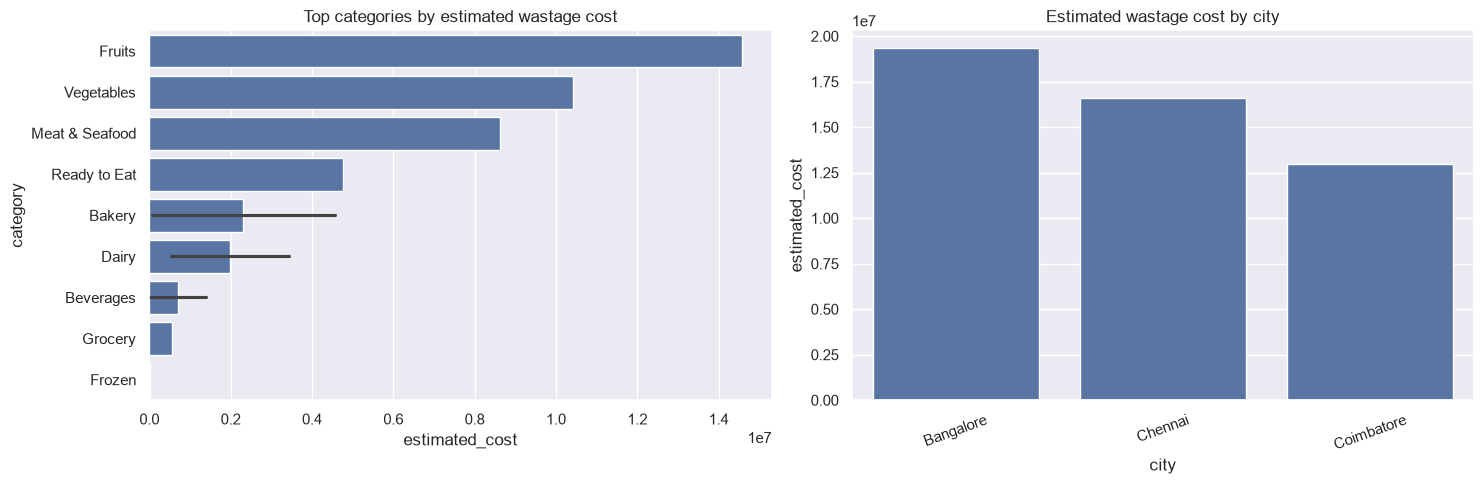

In [4]:
if not wastage.empty:
    wastage_enriched = wastage.merge(
        stores[["store_id", "city"]].drop_duplicates("store_id"),
        on="store_id", how="left", validate="many_to_one"
    ).merge(
        products[["sku_id", "product_name", "category", "is_perishable"]].drop_duplicates("sku_id"),
        on="sku_id", how="left", validate="many_to_one"
    )

    wastage_total = pd.DataFrame({
        "Metric": ["Wasted units", "Estimated wastage cost", "Wastage records"],
        "Value": [
            wastage_enriched["wasted_units"].sum(),
            wastage_enriched["estimated_cost"].sum(),
            len(wastage_enriched)
        ]
    })
    print("TOTAL WASTAGE")
    display(wastage_total)

    print("WASTAGE BY CATEGORY")
    wastage_category = wastage_enriched.groupby(
        ["category", "is_perishable"], dropna=False
    ).agg(
        wasted_units=("wasted_units", "sum"),
        estimated_cost=("estimated_cost", "sum"),
        records=("sku_id", "size")
    ).reset_index().sort_values("estimated_cost", ascending=False)
    display(wastage_category)

    print("WASTAGE BY CITY")
    display(wastage_enriched.groupby("city").agg(
        wasted_units=("wasted_units", "sum"),
        estimated_cost=("estimated_cost", "sum")
    ).sort_values("estimated_cost", ascending=False).reset_index())

    print("WASTAGE TYPE")
    display(wastage_enriched.groupby("wastage_type").agg(
        wasted_units=("wasted_units", "sum"),
        estimated_cost=("estimated_cost", "sum")
    ).sort_values("estimated_cost", ascending=False).reset_index())

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    cat_plot = wastage_category.sort_values("estimated_cost", ascending=False).head(12)
    sns.barplot(data=cat_plot, y="category", x="estimated_cost", ax=axes[0])
    axes[0].set_title("Top categories by estimated wastage cost")
    city_plot = wastage_enriched.groupby("city", as_index=False)["estimated_cost"].sum()
    sns.barplot(data=city_plot, x="city", y="estimated_cost", ax=axes[1])
    axes[1].set_title("Estimated wastage cost by city")
    axes[1].tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()
else:
    print("Wastage file is empty or unavailable.")

## 4. Supplier reliability and delivery performance

PURCHASE ORDER STATUS SUMMARY


,status,orders,ordered_units,received_units,rejected_units
0,Cancelled,489,15717,0,33
1,Delayed,4184,126766,126574,192
2,Received,35929,1176939,1175046,1893


SUPPLIER PERFORMANCE — ARRIVED ORDERS


,supplier_id,arrived_orders,mean_actual_lead_days,mean_delay_days,delayed_order_rate,ordered_units,received_units,rejected_units,fill_rate,rejection_rate
5,SUP006,2029,5.489897,0.489897,0.166585,36522,36522,0,1.000000,0.000000
13,SUP014,1787,1.497482,0.497482,0.166200,110794,110492,302,0.997274,0.002726
3,SUP004,2206,2.472348,0.472348,0.158658,39727,39727,0,1.000000,0.000000
11,SUP012,2768,2.442197,0.442197,0.152457,149472,149000,472,0.996842,0.003158
17,SUP018,3240,2.432099,0.432099,0.146914,41338,41311,27,0.999347,0.000653
6,SUP007,870,3.391954,0.391954,0.142529,50460,50322,138,0.997265,0.002735
15,SUP016,2286,3.381452,0.381452,0.129046,75438,75438,0,1.000000,0.000000
14,SUP015,2561,1.381882,0.381882,0.128856,51220,51220,0,1.000000,0.000000
16,SUP017,1248,3.294071,0.294071,0.094551,21474,21474,0,1.000000,0.000000
4,SUP005,2336,4.289812,0.289812,0.092466,23360,23360,0,1.000000,0.000000


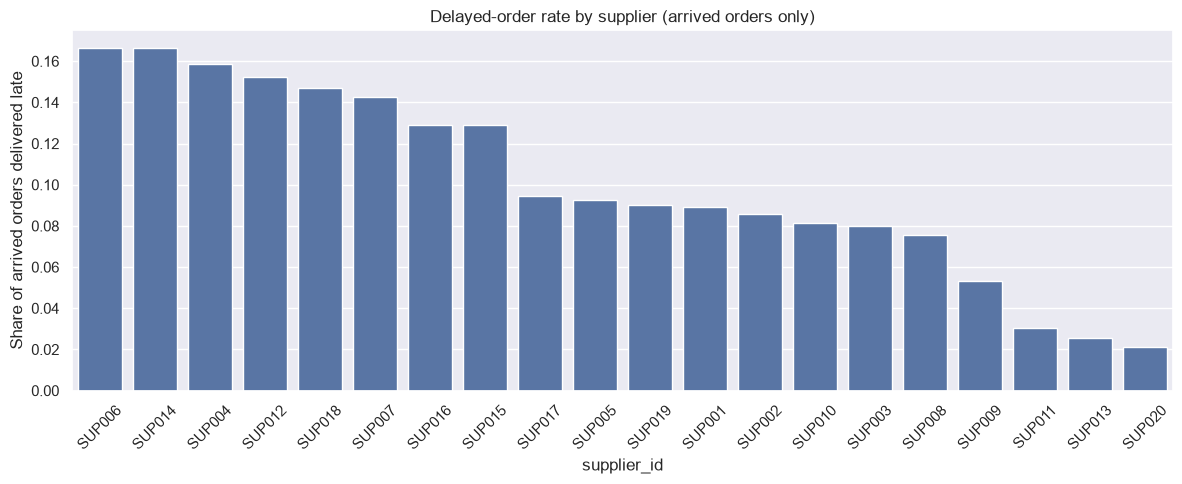

PO VS GOODS-RECEIPT RECONCILIATION — LARGEST DIFFERENCES


,po_id,ledger_received_units,ledger_rejected_units,received_quantity,quality_rejected_units,received_qty_difference
0,PO0000001,33,0,33,0,0
1,PO0000002,46,0,46,0,0
2,PO0000003,46,0,46,0,0
3,PO0000004,33,0,33,0,0
4,PO0000005,33,0,33,0,0
5,PO0000006,33,0,33,0,0
6,PO0000007,33,0,33,0,0
7,PO0000008,33,0,33,0,0
8,PO0000009,33,0,33,0,0
9,PO0000010,46,0,46,0,0


In [5]:
po = purchase_orders.copy()

# Calculate observed lead time only when both order and actual arrival dates exist.
po["actual_lead_time_days"] = (
    po["actual_arrival_date"] - po["order_date"]
).dt.days
po["expected_lead_time_days"] = (
    po["expected_arrival_date"] - po["order_date"]
).dt.days
po["arrival_delay_days_recalculated"] = (
    po["actual_arrival_date"] - po["expected_arrival_date"]
).dt.days

# Status-based summary; retain cancelled orders separately from delivered orders.
status_summary = po.groupby("status").agg(
    orders=("po_id", "count"),
    ordered_units=("ordered_quantity", "sum"),
    received_units=("received_quantity", "sum"),
    rejected_units=("quality_rejected_units", "sum")
).reset_index()
print("PURCHASE ORDER STATUS SUMMARY")
display(status_summary)

# Delivery performance among orders with an actual arrival date.
arrived = po[po["actual_arrival_date"].notna()].copy()
if not arrived.empty:
    supplier_perf = arrived.groupby("supplier_id").agg(
        arrived_orders=("po_id", "count"),
        mean_actual_lead_days=("actual_lead_time_days", "mean"),
        mean_delay_days=("arrival_delay_days_recalculated", "mean"),
        delayed_order_rate=("arrival_delay_days_recalculated", lambda x: (x > 0).mean()),
        ordered_units=("ordered_quantity", "sum"),
        received_units=("received_quantity", "sum"),
        rejected_units=("quality_rejected_units", "sum")
    ).reset_index()
    supplier_perf["fill_rate"] = (
        supplier_perf["received_units"] / supplier_perf["ordered_units"].replace(0, np.nan)
    )
    supplier_perf["rejection_rate"] = (
        supplier_perf["rejected_units"] /
        (supplier_perf["received_units"] + supplier_perf["rejected_units"]).replace(0, np.nan)
    )
    print("SUPPLIER PERFORMANCE — ARRIVED ORDERS")
    display(supplier_perf.sort_values(
        ["delayed_order_rate", "mean_delay_days"], ascending=False
    ))

    fig, ax = plt.subplots(figsize=(12, 5))
    supplier_plot = supplier_perf.sort_values("delayed_order_rate", ascending=False)
    sns.barplot(data=supplier_plot, x="supplier_id", y="delayed_order_rate", ax=ax)
    ax.set_title("Delayed-order rate by supplier (arrived orders only)")
    ax.set_ylabel("Share of arrived orders delivered late")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

# Cross-check PO receipts against the separate goods-receipt ledger where possible.
if not goods_receipts.empty:
    receipt_check = goods_receipts.groupby("po_id", as_index=False).agg(
        ledger_received_units=("quantity_received", "sum"),
        ledger_rejected_units=("quality_rejected_units", "sum")
    ).merge(
        po[["po_id", "received_quantity", "quality_rejected_units"]],
        on="po_id", how="left"
    )
    receipt_check["received_qty_difference"] = (
        receipt_check["ledger_received_units"] - receipt_check["received_quantity"]
    )
    print("PO VS GOODS-RECEIPT RECONCILIATION — LARGEST DIFFERENCES")
    display(receipt_check.reindex(
        receipt_check["received_qty_difference"].abs().sort_values(ascending=False).index
    ).head(20))

## 5. Latest inventory risk: stock cover and expiry flags

In [6]:
if not inventory.empty:
    inv = inventory.merge(
        stores[["store_id", "city"]].drop_duplicates("store_id"),
        on="store_id", how="left", validate="many_to_one"
    ).merge(
        products[["sku_id", "product_name", "category", "is_perishable", "cost"]].drop_duplicates("sku_id"),
        on="sku_id", how="left", validate="many_to_one"
    )

    inv["available_units"] = (
        inv["on_hand_units"] - inv["reserved_units"] + inv["in_transit_units"]
    ).clip(lower=0)
    inv["estimated_on_hand_value"] = inv["on_hand_units"] * inv["cost"]

    print("INVENTORY SNAPSHOT SUMMARY")
    display(pd.DataFrame({
        "Metric": [
            "Store-SKU records",
            "Total on-hand units",
            "Total in-transit units",
            "Records below reorder point",
            "Records with expiry risk flag",
            "Estimated on-hand product cost value"
        ],
        "Value": [
            len(inv),
            inv["on_hand_units"].sum(),
            inv["in_transit_units"].sum(),
            (inv["on_hand_units"] < inv["reorder_point_units"]).sum(),
            inv["expiry_risk_flag"].astype(bool).sum(),
            inv["estimated_on_hand_value"].sum()
        ]
    }))

    print("LOW-COVER / REORDER RISK — FIRST 25")
    display(inv.sort_values(
        ["days_of_cover_estimate", "on_hand_units"]
    )[[
        "city", "store_id", "sku_id", "product_name", "category",
        "on_hand_units", "in_transit_units", "reorder_point_units",
        "days_of_cover_estimate", "expiry_risk_flag"
    ]].head(25))

    print("EXPIRY-RISK RECORDS")
    display(inv[inv["expiry_risk_flag"].astype(bool)].sort_values(
        "days_of_cover_estimate"
    ).head(25))

INVENTORY SNAPSHOT SUMMARY


,Metric,Value
0,Store-SKU records,1805.00
1,Total on-hand units,31086.00
2,Total in-transit units,0.00
3,Records below reorder point,503.00
4,Records with expiry risk flag,259.00
5,Estimated on-hand product cost value,2834223.39


LOW-COVER / REORDER RISK — FIRST 25


,city,store_id,sku_id,product_name,category,on_hand_units,in_transit_units,reorder_point_units,days_of_cover_estimate,expiry_risk_flag
1,Bangalore,ST001,SKU0002,Onion,Vegetables,0,0,17,0.0,False
3,Bangalore,ST001,SKU0004,Carrot,Vegetables,0,0,4,0.0,False
4,Bangalore,ST001,SKU0005,Spinach,Vegetables,0,0,3,0.0,False
6,Bangalore,ST001,SKU0007,Capsicum,Vegetables,0,0,3,0.0,False
7,Bangalore,ST001,SKU0008,Brinjal,Vegetables,0,0,4,0.0,False
8,Bangalore,ST001,SKU0009,Okra,Vegetables,0,0,3,0.0,False
11,Bangalore,ST001,SKU0012,Green Chilli,Vegetables,0,0,2,0.0,False
16,Bangalore,ST001,SKU0017,Ginger,Vegetables,0,0,2,0.0,False
24,Bangalore,ST001,SKU0025,Papaya,Fruits,0,0,2,0.0,False
25,Bangalore,ST001,SKU0026,Watermelon,Fruits,0,0,2,0.0,False


EXPIRY-RISK RECORDS


,snapshot_date,store_id,sku_id,on_hand_units,reserved_units,in_transit_units,reorder_point_units,target_stock_units,max_stock_units,days_of_cover_estimate,expiry_risk_flag,city,product_name,category,is_perishable,cost,available_units,estimated_on_hand_value
474,2026-10-31,ST006,SKU0032,3,2,0,4,9,19,2.14,True,Bangalore,Milk 1L,Dairy,True,56.79,1,170.37
649,2026-10-31,ST008,SKU0032,3,0,0,4,9,19,2.14,True,Bangalore,Milk 1L,Dairy,True,56.79,3,170.37
1563,2026-10-31,ST018,SKU0032,4,0,0,4,9,19,2.86,True,Coimbatore,Milk 1L,Dairy,True,56.79,4,227.16
1470,2026-10-31,ST017,SKU0032,5,1,0,4,9,19,3.57,True,Coimbatore,Milk 1L,Dairy,True,56.79,4,283.95
1546,2026-10-31,ST018,SKU0015,4,1,0,3,8,15,4.00,True,Coimbatore,Beans,Vegetables,True,27.50,3,110.00
564,2026-10-31,ST007,SKU0032,6,2,0,4,9,19,4.29,True,Bangalore,Milk 1L,Dairy,True,56.79,4,340.74
835,2026-10-31,ST010,SKU0032,6,1,0,4,9,19,4.29,True,Chennai,Milk 1L,Dairy,True,56.79,5,340.74
1079,2026-10-31,ST013,SKU0007,5,1,0,3,8,15,4.55,True,Chennai,Capsicum,Vegetables,True,40.45,4,202.25
1073,2026-10-31,ST013,SKU0001,13,2,0,9,19,39,4.64,True,Chennai,Tomato,Vegetables,True,4.58,11,59.54
633,2026-10-31,ST008,SKU0015,5,1,0,3,8,15,5.00,True,Bangalore,Beans,Vegetables,True,27.50,4,137.50


## 6. Inter-store transfer analysis

In [7]:
if not transfers.empty:
    print("TRANSFER STATUS")
    display(transfers.groupby("status").agg(
        transfer_count=("transfer_id", "count"),
        units=("quantity_units", "sum"),
        total_transfer_cost=("transfer_cost", "sum"),
        avg_distance_km=("distance_km", "mean")
    ).reset_index())

    transfer_summary = transfers.groupby(
        ["from_store_id", "to_store_id", "status"]
    ).agg(
        transfers=("transfer_id", "count"),
        units=("quantity_units", "sum"),
        cost=("transfer_cost", "sum"),
        avg_distance_km=("distance_km", "mean")
    ).reset_index().sort_values("cost", ascending=False)

    print("TOP TRANSFER LANES BY COST")
    display(transfer_summary.head(20))
    print("Cold-chain required transfers:", int(transfers["cold_chain_required"].astype(bool).sum()))
    print("Intercity transfers:", int(transfers["is_intercity"].astype(bool).sum()))
else:
    print("Transfer table is empty or unavailable.")

TRANSFER STATUS


,status,transfer_count,units,total_transfer_cost,avg_distance_km
0,Cancelled,42,889,41096.62,129.202381
1,Completed,260,5518,258861.37,137.260000
2,Pending,107,2302,115553.55,155.135514
3,Rejected,91,1814,92258.44,140.075824


TOP TRANSFER LANES BY COST


,from_store_id,to_store_id,status,transfers,units,cost,avg_distance_km
67,ST003,ST018,Completed,3,71,5948.46,269.066667
207,ST010,ST019,Completed,3,59,5837.87,246.066667
60,ST003,ST009,Completed,3,74,4897.38,231.933333
279,ST014,ST008,Completed,3,56,4764.29,192.566667
141,ST007,ST012,Completed,4,70,4622.80,172.250000
333,ST017,ST007,Completed,4,112,4414.31,191.200000
356,ST018,ST014,Pending,2,39,4204.66,280.050000
256,ST013,ST008,Completed,2,41,4068.33,254.350000
397,ST020,ST012,Completed,2,27,3779.97,251.450000
118,ST006,ST009,Rejected,2,50,3722.94,213.450000


Cold-chain required transfers: 225
Intercity transfers: 346


## 7. Corrected weekday analysis: total demand and per-store demand

WEEKDAY PATTERN — TOTAL AND PER-STORE MEASURES


,weekday,avg_total_daily_demand,avg_demand_per_store,avg_total_daily_revenue
0,Monday,1611.634615,80.581731,91063.325962
1,Tuesday,1602.519231,80.125962,90019.165962
2,Wednesday,1618.826923,80.941346,90753.420962
3,Thursday,1617.673077,80.883654,90155.858269
4,Friday,1616.903846,80.845192,90924.485385
5,Saturday,1876.452830,93.822642,105512.722830
6,Sunday,1869.634615,93.481731,104533.095000


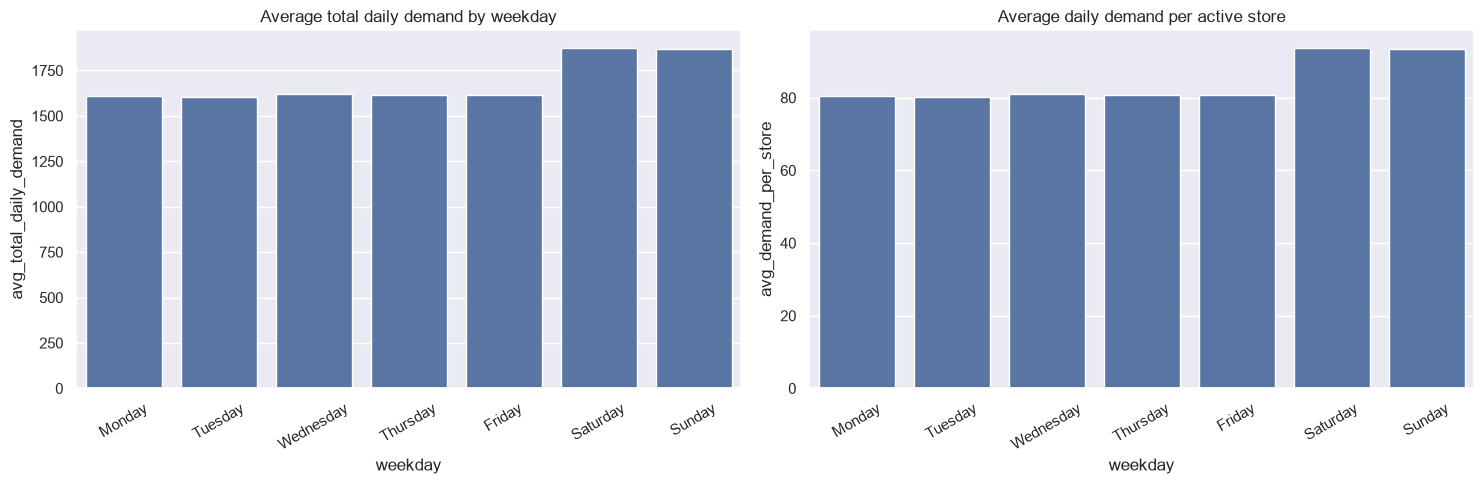

In [8]:
# The earlier EDA chart averaged over store-SKU rows.
# Here we separately show daily total demand and mean demand per active store.
sales_city = sales.merge(
    stores[["store_id", "city"]].drop_duplicates("store_id"),
    on="store_id", how="left", validate="many_to_one"
)
sales_city["weekday"] = sales_city["date"].dt.day_name()

daily_totals = sales_city.groupby(["date", "weekday"]).agg(
    total_demand=("demand_units", "sum"),
    total_fulfilled=("quantity", "sum"),
    total_revenue=("revenue", "sum"),
    active_stores=("store_id", "nunique")
).reset_index()
daily_totals["demand_per_active_store"] = (
    daily_totals["total_demand"] / daily_totals["active_stores"].replace(0, np.nan)
)
daily_totals["fulfilled_per_active_store"] = (
    daily_totals["total_fulfilled"] / daily_totals["active_stores"].replace(0, np.nan)
)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_totals = daily_totals.groupby("weekday").agg(
    avg_total_daily_demand=("total_demand", "mean"),
    avg_demand_per_store=("demand_per_active_store", "mean"),
    avg_total_daily_revenue=("total_revenue", "mean")
).reindex(weekday_order).reset_index()

print("WEEKDAY PATTERN — TOTAL AND PER-STORE MEASURES")
display(weekday_totals)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=weekday_totals, x="weekday", y="avg_total_daily_demand", ax=axes[0])
axes[0].set_title("Average total daily demand by weekday")
axes[0].tick_params(axis="x", rotation=30)
sns.barplot(data=weekday_totals, x="weekday", y="avg_demand_per_store", ax=axes[1])
axes[1].set_title("Average daily demand per active store")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 8. Prioritized business opportunity list

In [9]:
# Rank by estimated lost gross profit, and show wastage cost separately.
priority = sku_store_loss.groupby(
    ["city", "store_id", "sku_id", "product_name", "category"]
).agg(
    lost_units=("lost_units", "sum"),
    estimated_lost_revenue=("estimated_lost_revenue", "sum"),
    estimated_lost_gross_profit=("estimated_lost_gross_profit", "sum")
).reset_index()

if not wastage.empty:
    w_join = wastage.merge(
        stores[["store_id", "city"]].drop_duplicates("store_id"),
        on="store_id", how="left"
    ).merge(
        products[["sku_id", "product_name", "category"]].drop_duplicates("sku_id"),
        on="sku_id", how="left"
    )
    w_rank = w_join.groupby(
        ["city", "store_id", "sku_id", "product_name", "category"]
    )["estimated_cost"].sum().reset_index(name="estimated_wastage_cost")
    priority = priority.merge(
        w_rank, on=["city", "store_id", "sku_id", "product_name", "category"],
        how="left"
    )
else:
    priority["estimated_wastage_cost"] = 0

priority["estimated_wastage_cost"] = priority["estimated_wastage_cost"].fillna(0)
priority["combined_opportunity_indicator"] = (
    priority["estimated_lost_gross_profit"] + priority["estimated_wastage_cost"]
)

print("TOP 30 STORE-SKU OPPORTUNITIES")
display(priority.sort_values(
    "combined_opportunity_indicator", ascending=False
).head(30))

TOP 30 STORE-SKU OPPORTUNITIES


,city,store_id,sku_id,product_name,category,lost_units,estimated_lost_revenue,estimated_lost_gross_profit,estimated_wastage_cost,combined_opportunity_indicator
1517,Coimbatore,ST017,SKU0082,Fish 500g,Meat & Seafood,62,14770.26,2954.30,320572.38,323526.68
693,Bangalore,ST008,SKU0082,Fish 500g,Meat & Seafood,85,20249.55,4050.25,317713.53,321763.78
520,Bangalore,ST006,SKU0082,Fish 500g,Meat & Seafood,99,23584.77,4717.35,305515.77,310233.12
1700,Coimbatore,ST019,SKU0082,Fish 500g,Meat & Seafood,69,16437.87,3287.85,304562.82,307850.67
1238,Chennai,ST014,SKU0082,Fish 500g,Meat & Seafood,78,18581.94,3716.70,303038.10,306754.80
72,Bangalore,ST001,SKU0082,Fish 500g,Meat & Seafood,98,23346.54,4669.70,300369.84,305039.54
256,Bangalore,ST003,SKU0082,Fish 500g,Meat & Seafood,97,23108.31,4622.05,297320.40,301942.45
786,Chennai,ST009,SKU0082,Fish 500g,Meat & Seafood,79,18529.52,3764.35,297129.81,300894.16
603,Bangalore,ST007,SKU0082,Fish 500g,Meat & Seafood,73,17390.79,3478.45,291030.93,294509.38
1786,Coimbatore,ST020,SKU0082,Fish 500g,Meat & Seafood,65,15484.95,3097.25,288934.44,292031.69


## 9. Findings and decisions — fill after running

Do not claim that an action would have prevented a loss until it is tested in a counterfactual simulation.

Record:
- Highest-loss cities/stores/SKUs.
- Categories with the greatest lost-sales opportunity.
- Categories and stores with the highest wastage cost.
- Suppliers with high delay rates, low fill rates or high rejection rates.
- Store-SKU records with low days of cover or expiry risk.
- Transfer lanes that appear operationally useful or expensive.
- Weekday/weekend differences using both total and per-store measures.

## 10. Agent requirements derived from this analysis

1. **Demand Forecasting Agent:** forecast demand at store × SKU × day grain.
2. **Inventory Optimization Agent:** use forecast, available stock, reorder point, lead time and expiry risk.
3. **Supplier Intelligence Agent:** estimate supplier-specific delay and fill-rate risk.
4. **Transfer & Logistics Agent:** compare transfer cost and transit time with replenishment alternatives.
5. **Pricing Intelligence Agent:** evaluate markdowns for expiry-risk stock while protecting margin.
6. **Decision Orchestrator:** compare actions using expected profit, service level, wastage, cost and confidence.

### Next notebook
**03 — Feature Engineering and Demand Forecasting.** Use the chronological training and validation splits; keep the test set untouched until final evaluation.